In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from windrose import WindroseAxes

In [15]:
df = pd.read_csv('reanalysis/reanalysis_2006.csv')
print(df.head())

             Date_time  WS100  WD100
0  2006-01-01 00:00:00  8.515  243.1
1  2006-01-01 01:00:00  8.379  246.2
2  2006-01-01 02:00:00  7.772  245.6
3  2006-01-01 03:00:00  7.852  241.6
4  2006-01-01 04:00:00  8.319  239.5


In [16]:
dt_index = pd.to_datetime(df["Date_time"], utc=True)
df = df.set_index(dt_index)
df.index.name = "Date_time"
df = df.sort_index()
df = df.drop(columns=["Date_time"])
print(df.head())

                           WS100  WD100
Date_time                              
2006-01-01 00:00:00+00:00  8.515  243.1
2006-01-01 01:00:00+00:00  8.379  246.2
2006-01-01 02:00:00+00:00  7.772  245.6
2006-01-01 03:00:00+00:00  7.852  241.6
2006-01-01 04:00:00+00:00  8.319  239.5


In [17]:
print(len(df) - (365*24))

0


In [18]:
print(np.sum(df.index.duplicated()))

0


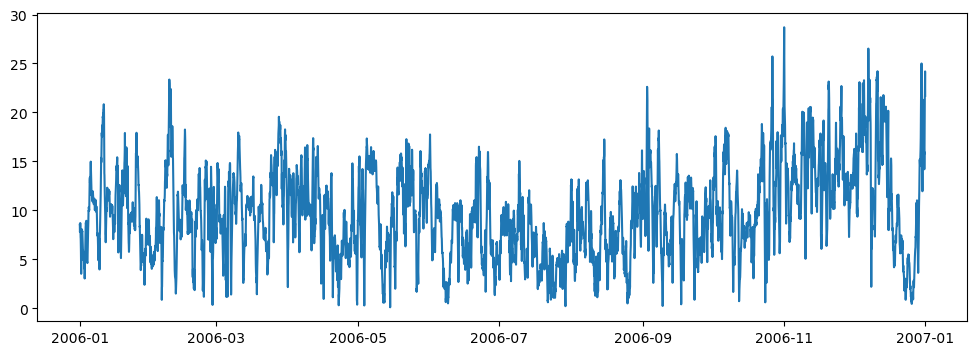

In [19]:
plt.figure(figsize=(12,4))
plt.plot(df['WS100'])
plt.show()

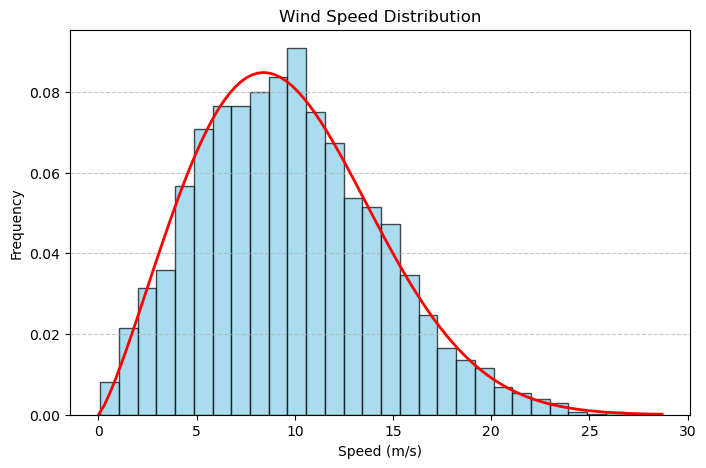

In [20]:
shape, loc, scale = stats.weibull_min.fit(df['WS100'], floc=0)

plt.figure(figsize=(8, 5))
plt.hist(df['WS100'], bins=30, density=True, color='skyblue', edgecolor='black', alpha=0.7)

x = np.linspace(0, max(df['WS100']), 100)
plt.plot(x, stats.weibull_min.pdf(x, shape, loc, scale), 'r-', lw=2, label='Weibull Fit')

plt.title('Wind Speed Distribution')
plt.xlabel('Speed (m/s)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

[Text(0, 0, ''),
 Text(0, 3, '3%'),
 Text(0, 6, '6%'),
 Text(0, 9, '9%'),
 Text(0, 12, '12%')]

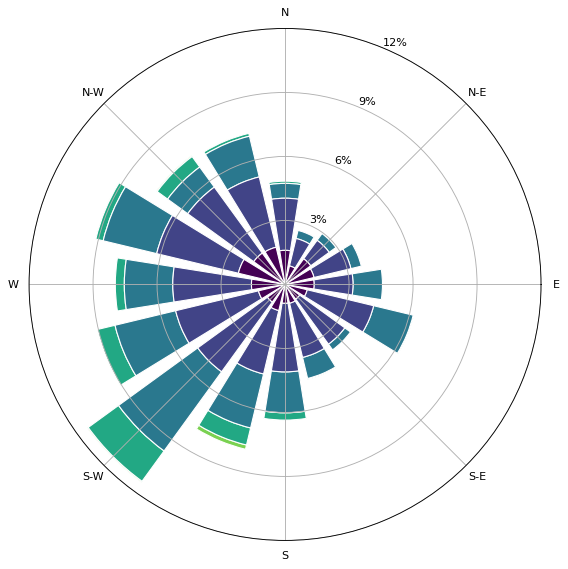

In [45]:
ax = WindroseAxes.from_ax()

ax.bar(df['WD100'], df['WS100'], normed=True, opening=0.8, edgecolor='white')

ax.set_yticks(np.arange(0, 15, 3))
ax.set_yticklabels(['', '3%', '6%', '9%', '12%'])